# Inference efficiency

Forward-only inference with synthetic inputs already on the selected device.
No training or checkpoint download is required for this architecture benchmark.
Results are saved after each model/batch combination in a timestamped directory.
Charts contain only axes and model labels; error bars span repeat-average timings.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import platform
import sys

repo_root = Path.cwd()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root / "src"))

import pandas as pd
import torch
from IPython.display import Image, display
from models import get_classification_model
from benchmark import benchmark_inference
from utils.io import save_inference_results
from visualization import plot_inference_results

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
BATCH_SIZES = (1, 2, 4, 8, 16, 32)
IMAGE_SIZE = (224, 224)
NUM_ITERATIONS = 100
WARMUP_ITERATIONS = 50
REPEATS = 5
PRETRAINED = False
NUM_CLASSES = 37
DTYPE = torch.float32
SEED = 42
MODEL_NAMES = {
    "ConvNeXt Tiny": ("convnext_tiny", "convnext_tiny"),
    "Swin Transformer Tiny": ("swin_tiny", "swin_tiny_patch4_window7_224"),
    "ResNet-50": ("resnet50", "resnet50"),
}
OUTPUT_DIR = repo_root / "results" / "efficiency" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
print(f"Device: {DEVICE} | Results: {OUTPUT_DIR}")


/Users/kasrasadatsharifi/Library/Caches/pypoetry/virtualenvs/convnexts-2-MddwQV-py3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: mps | Results: /Users/kasrasadatsharifi/SideProjects/ConvNeXts/results/efficiency/20261027T175532629512Z


In [2]:
torch.manual_seed(SEED)
metadata = {
    "image_size": IMAGE_SIZE,
    "num_classes": NUM_CLASSES,
    "hardware": torch.cuda.get_device_name() if DEVICE == "cuda" else platform.processor() or platform.machine(),
    "versions": {name: version(name) for name in ("torch", "torchvision", "timm")},
    "cpu_threads": torch.get_num_threads(),
    "seed": SEED,
}
results = []
for model_name, (model_id, timm_name) in MODEL_NAMES.items():
    model = get_classification_model(timm_name, pretrained=PRETRAINED, num_classes=NUM_CLASSES).to(dtype=DTYPE)
    for batch_size in BATCH_SIZES:
        inputs = torch.randn(batch_size, 3, *IMAGE_SIZE, device=DEVICE, dtype=DTYPE)
        result = benchmark_inference(model, inputs, DEVICE, NUM_ITERATIONS, WARMUP_ITERATIONS, REPEATS)
        results.append({"model_name": model_name, "model_id": model_id, "timm_model": timm_name, **result})
        saved = save_inference_results(results, OUTPUT_DIR, metadata)
        print(f"{model_name}, batch size {batch_size}: {result['batch_latency_ms']:.3f} ms/batch, "
              f"{result['throughput_images_per_second']:.1f} images/s")
        del inputs
    model.to("cpu")
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE == "mps":
        torch.mps.empty_cache()


ConvNeXt Tiny, batch size 1: 2.932 ms/batch, 341.1 images/s
ConvNeXt Tiny, batch size 2: 5.357 ms/batch, 373.3 images/s
ConvNeXt Tiny, batch size 4: 10.156 ms/batch, 393.9 images/s
ConvNeXt Tiny, batch size 8: 20.084 ms/batch, 398.3 images/s
ConvNeXt Tiny, batch size 16: 40.727 ms/batch, 392.9 images/s
ConvNeXt Tiny, batch size 32: 82.269 ms/batch, 389.0 images/s
Swin Transformer Tiny, batch size 1: 3.942 ms/batch, 253.6 images/s
Swin Transformer Tiny, batch size 2: 7.036 ms/batch, 284.3 images/s
Swin Transformer Tiny, batch size 4: 13.041 ms/batch, 306.7 images/s
Swin Transformer Tiny, batch size 8: 25.302 ms/batch, 316.2 images/s
Swin Transformer Tiny, batch size 16: 50.313 ms/batch, 318.0 images/s
Swin Transformer Tiny, batch size 32: 100.006 ms/batch, 320.0 images/s
ResNet-50, batch size 1: 3.512 ms/batch, 284.8 images/s
ResNet-50, batch size 2: 5.094 ms/batch, 392.6 images/s
ResNet-50, batch size 4: 8.943 ms/batch, 447.3 images/s
ResNet-50, batch size 8: 17.213 ms/batch, 464.8 ima

,model_name,model_id,timm_model,device,dtype,batch_size,num_iterations,warmup_iterations,repeats,batch_latency_ms,batch_latency_min_ms,batch_latency_max_ms,throughput_images_per_second,throughput_min_images_per_second,throughput_max_images_per_second,flops_per_batch,gflops_per_image,parameters
0,ConvNeXt Tiny,convnext_tiny,convnext_tiny,mps,torch.float32,1,100,50,5,2.932114,2.905473,2.966243,341.050889,337.126806,344.178000,8909583360,8.909583,27848581
1,ConvNeXt Tiny,convnext_tiny,convnext_tiny,mps,torch.float32,2,100,50,5,5.357399,5.337181,5.367027,373.315501,372.645810,374.729667,17819166720,8.909583,27848581
2,ConvNeXt Tiny,convnext_tiny,convnext_tiny,mps,torch.float32,4,100,50,5,10.155506,10.129565,10.165614,393.875014,393.483374,394.883674,35638333440,8.909583,27848581
3,ConvNeXt Tiny,convnext_tiny,convnext_tiny,mps,torch.float32,8,100,50,5,20.083858,20.052562,20.254109,398.329844,394.981578,398.951506,71276666880,8.909583,27848581
4,ConvNeXt Tiny,convnext_tiny,convnext_tiny,mps,torch.float32,16,100,50,5,40.727010,40.717381,40.946280,392.859677,390.755888,392.952580,142553333760,8.909583,27848581
5,ConvNeXt Tiny,convnext_tiny,convnext_tiny,mps,torch.float32,32,100,50,5,82.268908,81.940615,82.481462,388.968331,387.965967,390.526723,285106667520,8.909583,27848581
6,Swin Transformer Tiny,swin_tiny,swin_tiny_patch4_window7_224,mps,torch.float32,1,100,50,5,3.942460,3.931455,3.986783,253.648737,250.828780,254.358728,8979654144,8.979654,27547807
7,Swin Transformer Tiny,swin_tiny,swin_tiny_patch4_window7_224,mps,torch.float32,2,100,50,5,7.035895,7.024715,7.070985,284.256675,282.846025,284.709076,17959308288,8.979654,27547807
8,Swin Transformer Tiny,swin_tiny,swin_tiny_patch4_window7_224,mps,torch.float32,4,100,50,5,13.041481,12.999751,13.070193,306.713626,306.039850,307.698195,35918616576,8.979654,27547807
9,Swin Transformer Tiny,swin_tiny,swin_tiny_patch4_window7_224,mps,torch.float32,8,100,50,5,25.302062,25.282483,25.676074,316.179758,311.574112,316.424618,71837233152,8.979654,27547807


inference_batch_1.png


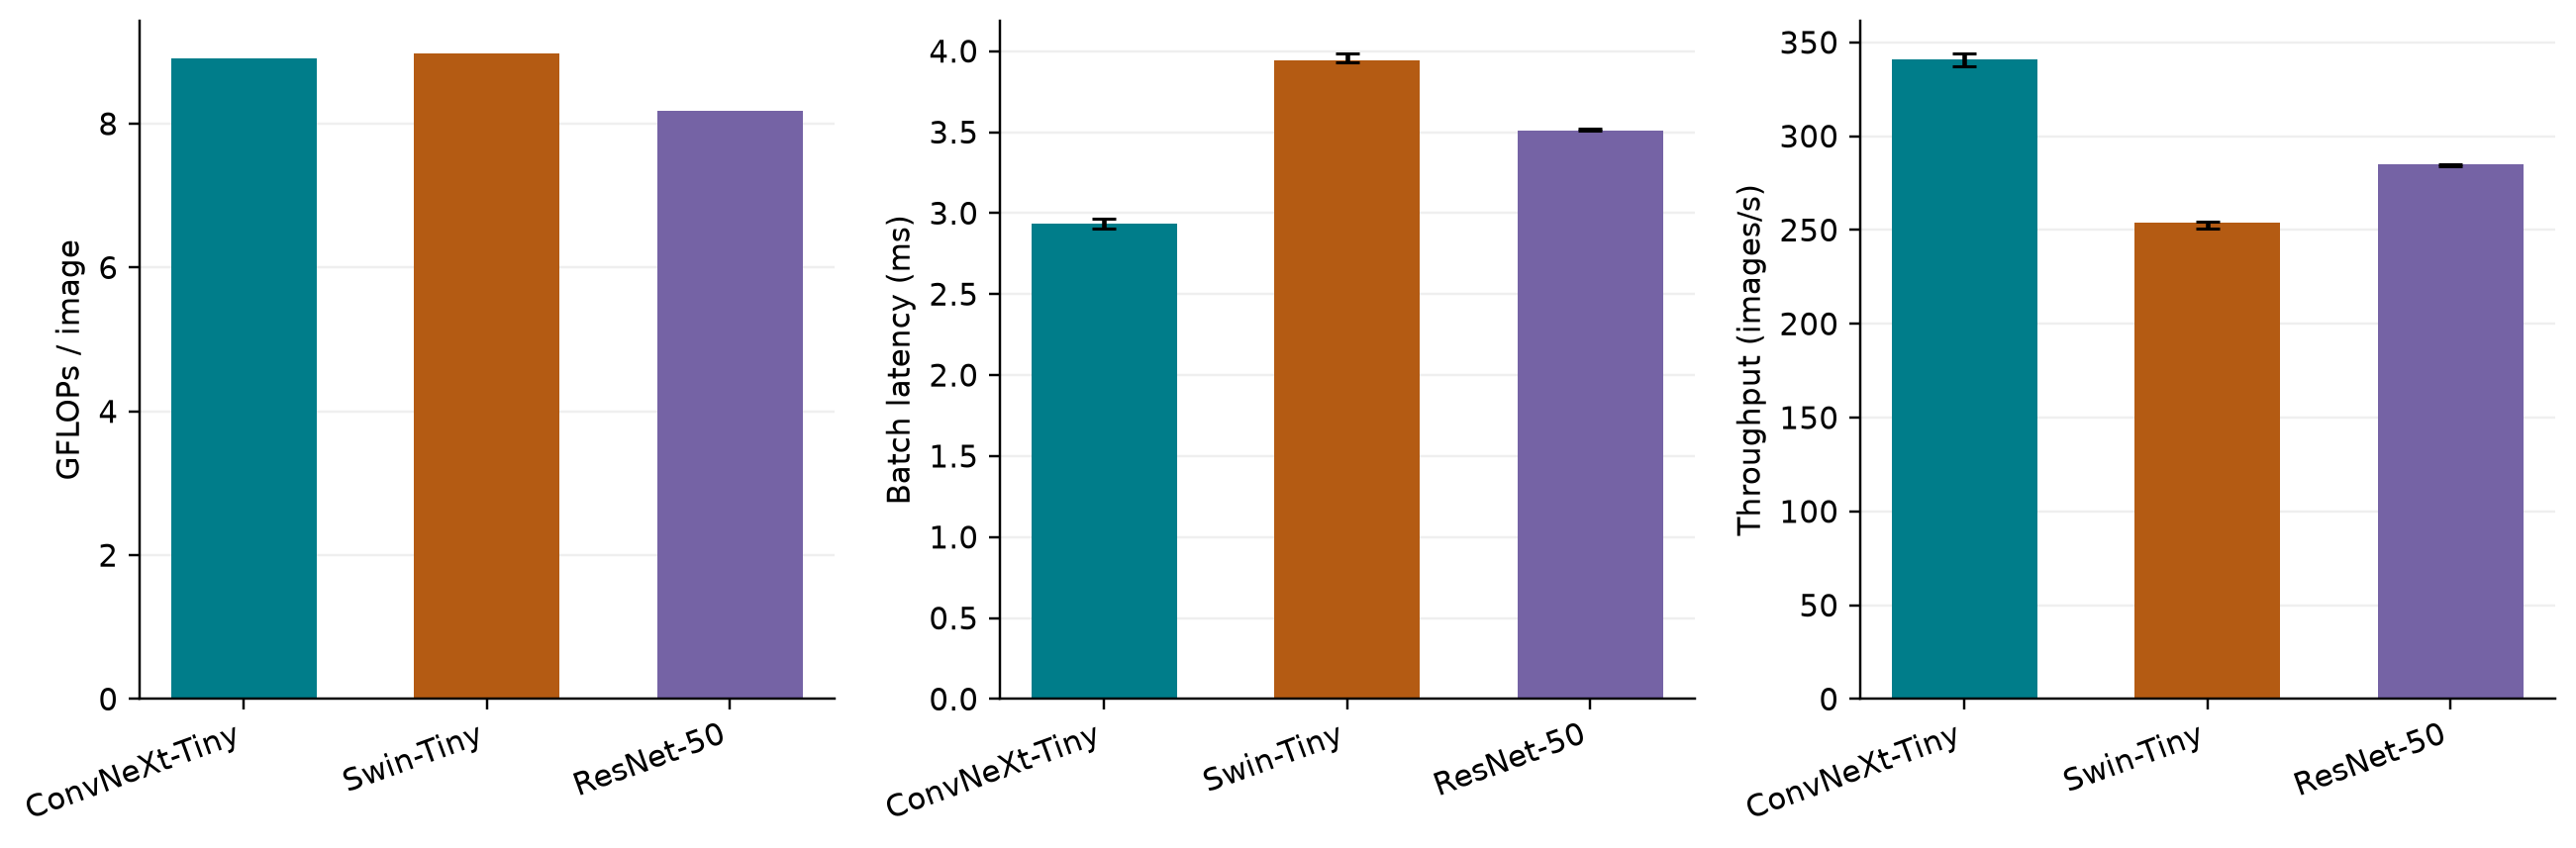

inference_batch_2.png


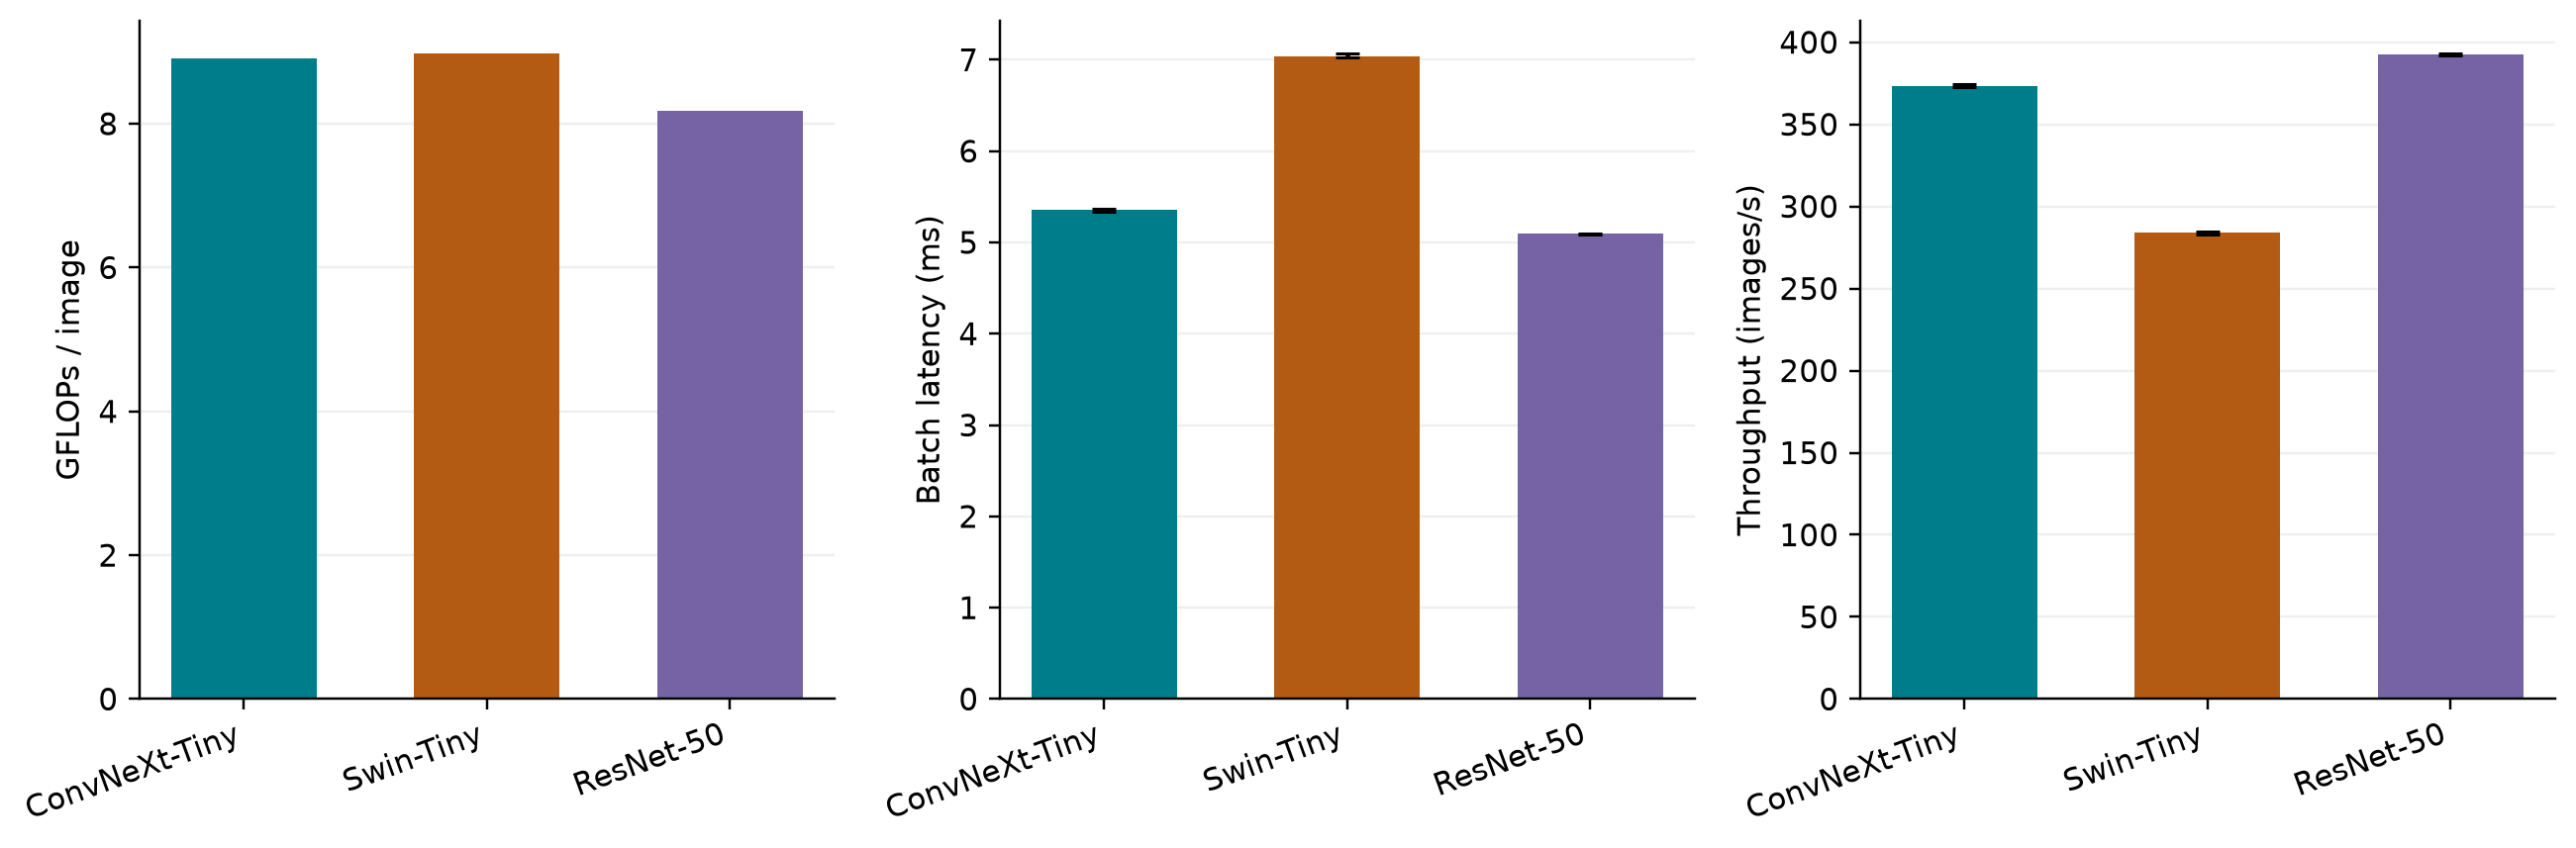

inference_batch_4.png


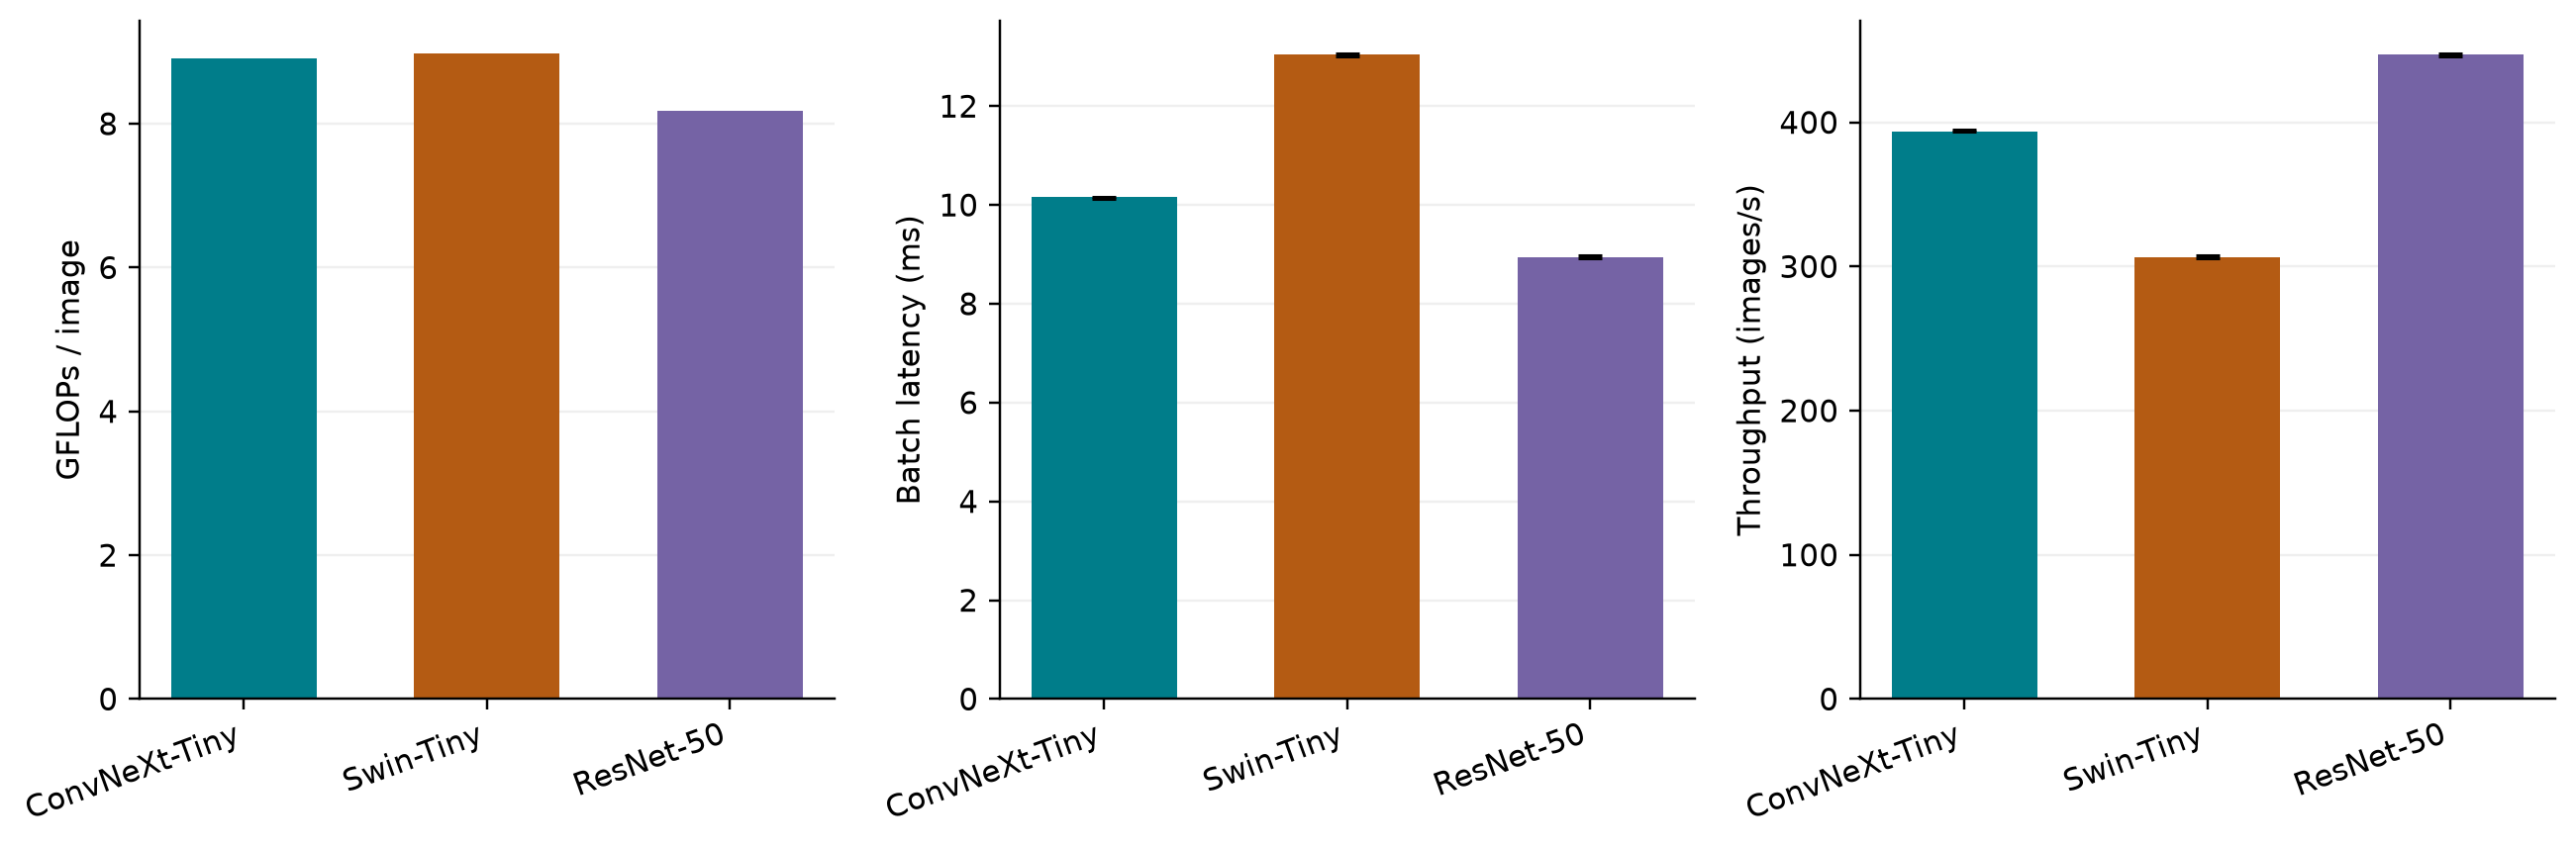

inference_batch_8.png


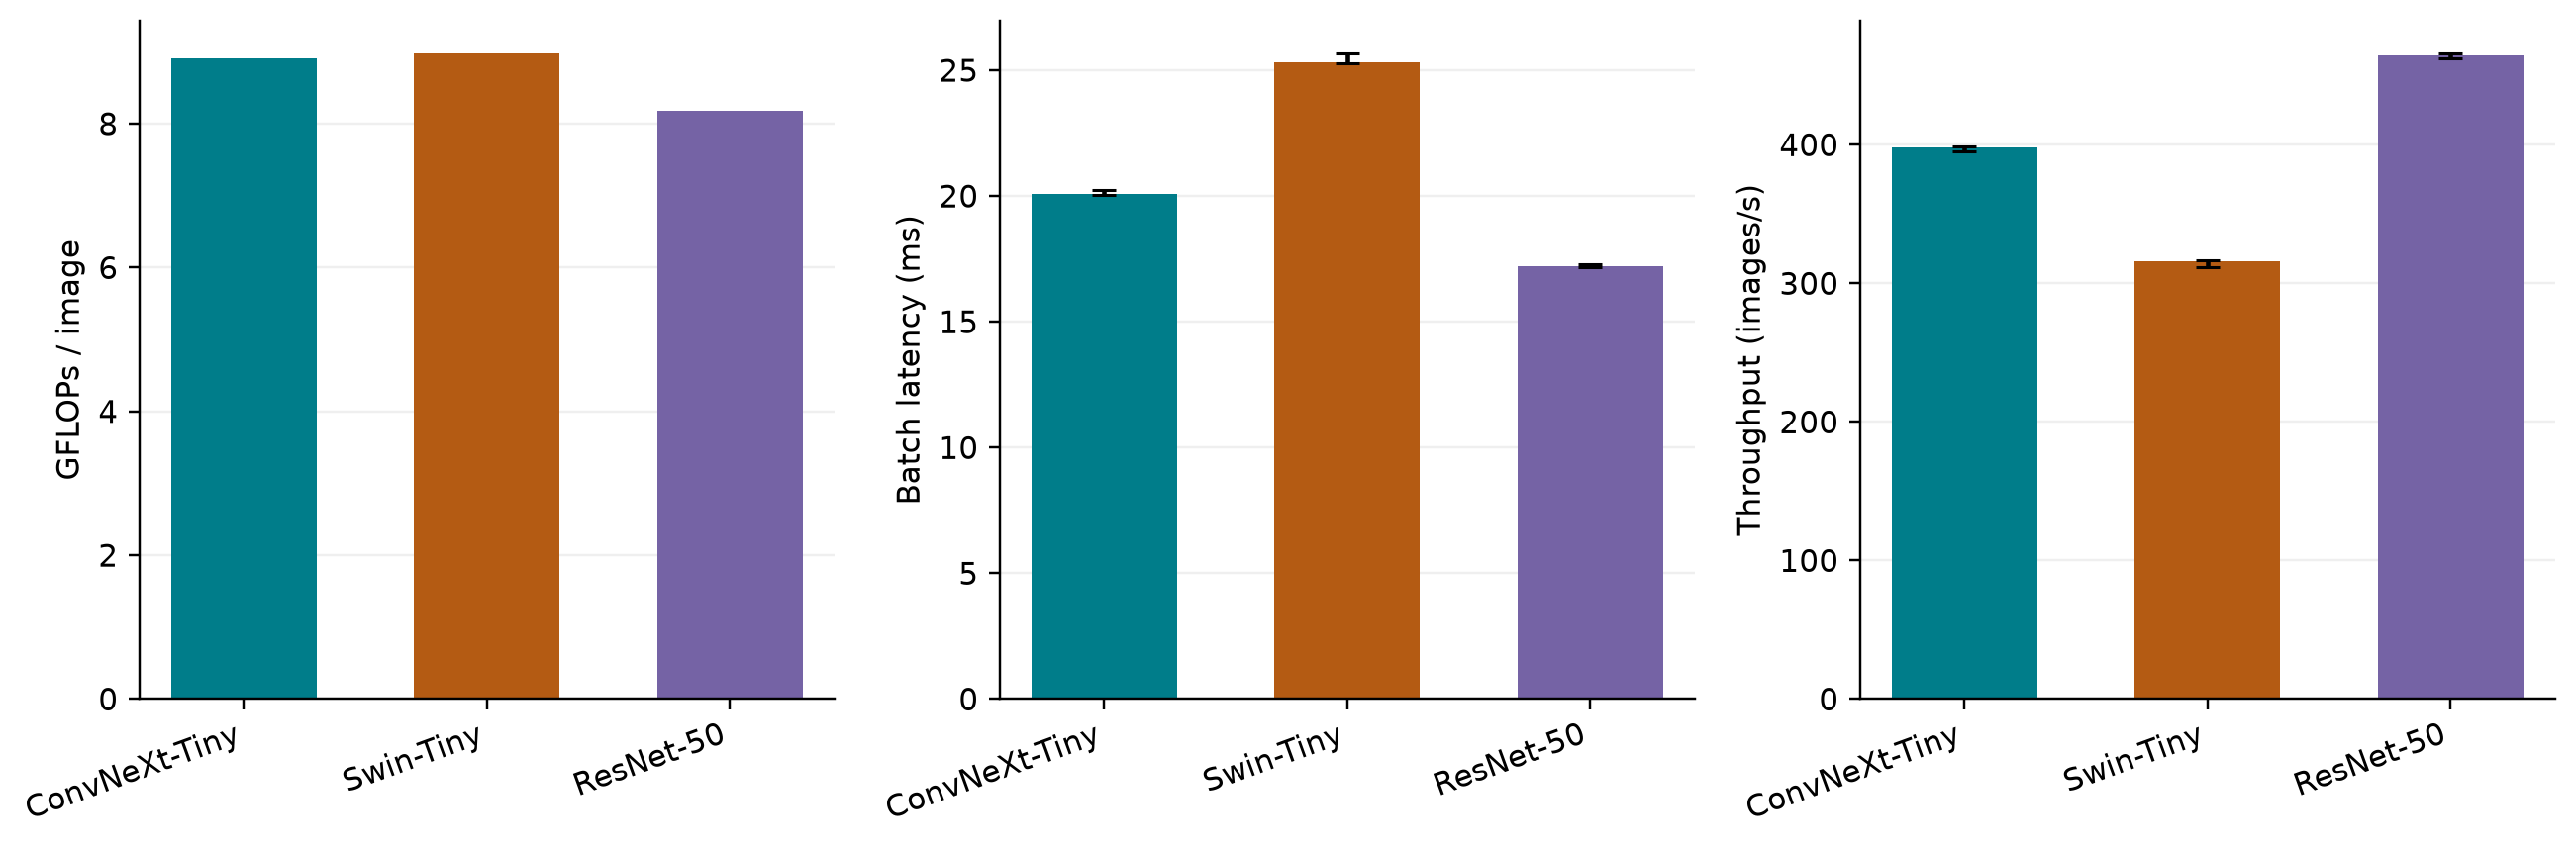

inference_batch_16.png


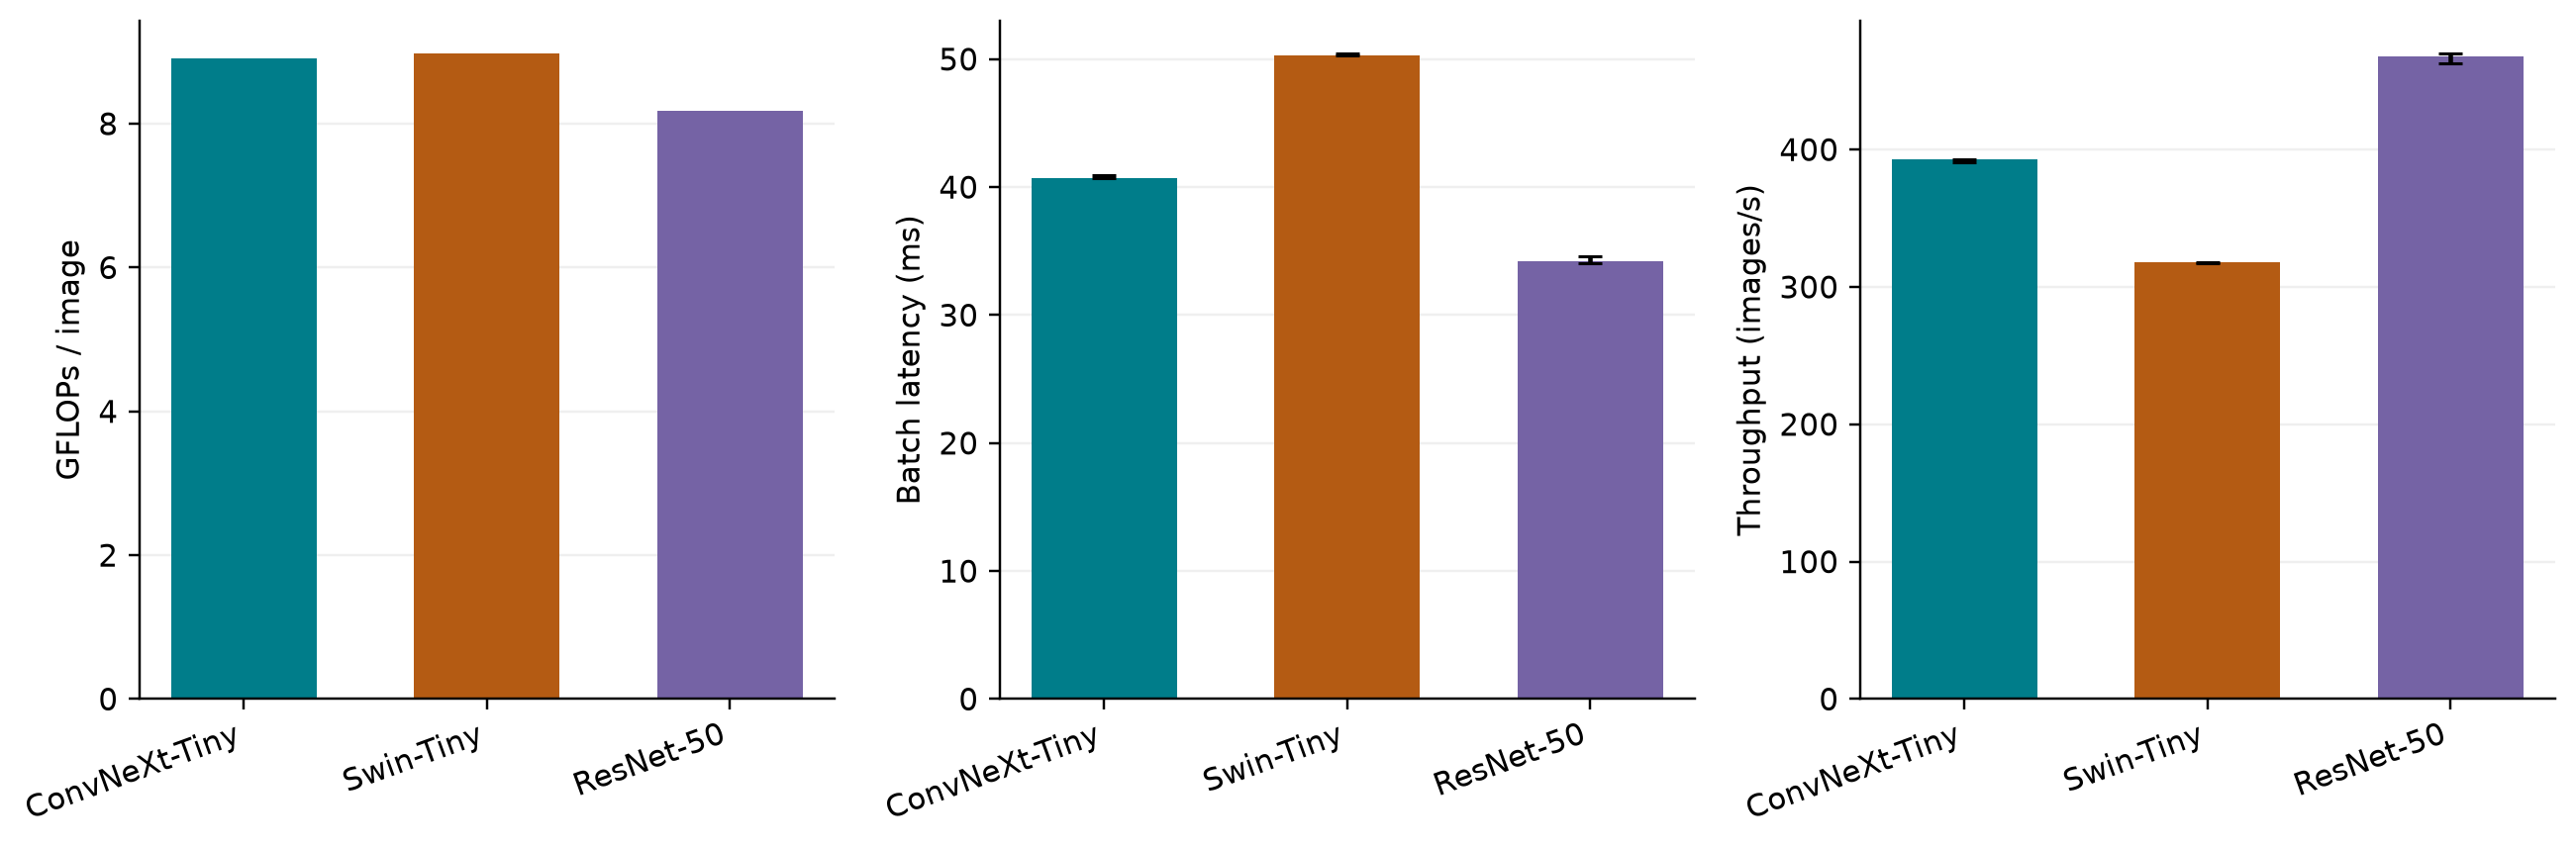

inference_batch_32.png


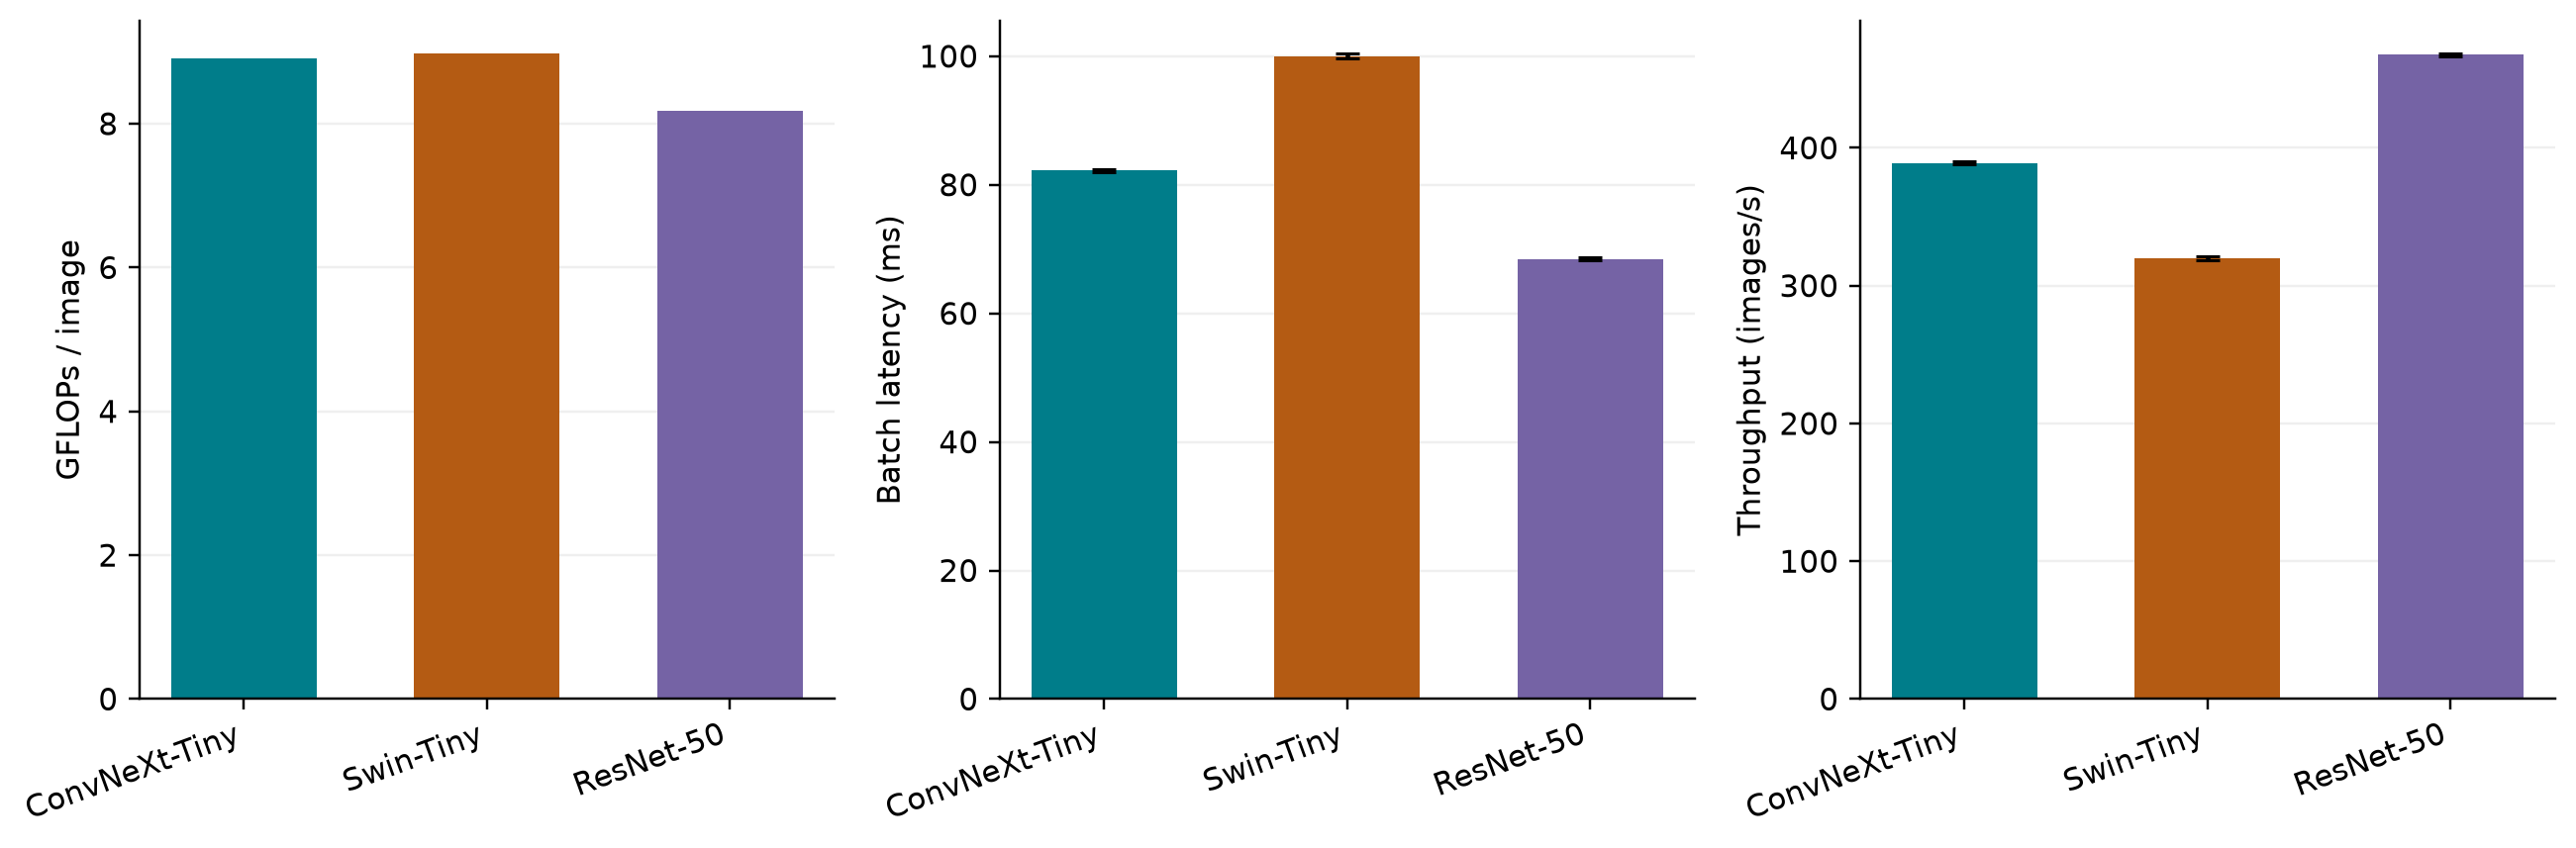

Saved: {'json': PosixPath('/Users/kasrasadatsharifi/SideProjects/ConvNeXts/results/efficiency/20261027T175532629512Z/inference_results.json'), 'csv': PosixPath('/Users/kasrasadatsharifi/SideProjects/ConvNeXts/results/efficiency/20261027T175532629512Z/inference_summary.csv')}


In [3]:
display(pd.read_csv(OUTPUT_DIR / "inference_summary.csv"))
for path in plot_inference_results(results, OUTPUT_DIR):
    print(path.name)
    display(Image(filename=str(path)))
print("Saved:", saved)
